# SafeSathi — Voice Distress Classifier (real audio)

Builds the model behind the AI service's voice analysis: given a short clip recorded by the phone, estimate the
probability that it contains a **scream**, as opposed to ordinary **speech** or some **other sound**
(dog bark, siren, baby crying, laughter, door slam …).

### Why this notebook replaces the old one
The old notebook invented four numbers per clip (`pitch`, `loudness`, `centroid`, `jitter`) by sampling
Gaussians whose means were chosen by hand, then "trained" on them. This version never touches synthetic data:
* **Screams** — 71 real scream recordings (female/male, studio and freesound clips)
* **Normal speech** — 69 real clean-speech recordings
* **Other sounds** — 304 real environmental recordings from **ESC-50** (Piczak, ACM MM 2015), 38 categories,
  deliberately including the sounds most likely to be mistaken for a scream (baby crying, laughing, sirens, dog, glass).

### Pipeline
loading → cleaning → feature extraction → EDA → feature engineering/selection → clip-wise split →
5 models compared → tuning → calibration → evaluation (window **and** clip level) → robustness (noise, phone codec) → export

### Honest scope note
There is no scream/fear corpus reachable from GitHub that also includes *fearful speech*, so this model has **no
`fear_distress` class** and the service reports `fear_probability = 0`. Section 4b shows how to add it in two minutes if you
download RAVDESS (emotion code `06` = fearful) — that cell is written but **was not executed** in this build.
Spoken *keywords* ("help", "bachao") are **not** this model's job: the phone's on-device speech recogniser handles those.

In [1]:
import hashlib, io, json, sys, time, subprocess, shutil, tempfile, urllib.request, urllib.parse, csv, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import librosa, librosa.display
import joblib, sklearn

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, roc_curve, auc,
                             precision_recall_curve, average_precision_score, brier_score_loss, balanced_accuracy_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "app").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from app.utils import audio_features as AF            # <- the SAME module the FastAPI service imports

RAW = PROJECT_ROOT / "data" / "raw" / "audio"
DATA_DIR, ARTIFACTS_DIR = PROJECT_ROOT / "data", PROJECT_ROOT / "app" / "ml_artifacts"
for d in (RAW / "scream", RAW / "speech", RAW / "other", ARTIFACTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", PROJECT_ROOT, "| sklearn", sklearn.__version__, "| librosa", librosa.__version__)
print(f"{len(AF.FEATURE_NAMES)} acoustic features per {AF.WIN_S}s window @ {AF.SR} Hz")

project root: /home/claude/out/ai-services | sklearn 1.8.0 | librosa 0.11.0
40 acoustic features per 1.5s window @ 16000 Hz


## 1. Data loading
All files are pulled from public GitHub repositories and cached in `data/raw/audio/`.
* scream + speech: `Varun-310/SCREAM` (`positive/` and `negative/clnsp*.wav`)
* environmental sounds: `karolpiczak/ESC-50` (8 clips from each of 38 categories, chosen from `meta/esc50.csv`)

In [2]:
VARUN = "https://raw.githubusercontent.com/Varun-310/SCREAM/main"
ESC = "https://raw.githubusercontent.com/karolpiczak/ESC-50/master"
SCREAM_FILES = (["169810__missozzy__female-scream-01_0.wav", "169810__missozzy__female-scream-01_1.wav",
                 "319258__ramston__woman-screaming-of-fear.wav", "343916__reitanna__screaming-and-why.wav",
                 "359154__horroraudio__muffled-female-cry.wav", "Scream+25.wav", "Scream+26.wav", "abuse_female_scream.wav",
                 "abuse_female_screaming-and-why.wav"]
                + [f"damm_{i}.wav" for i in range(8)]
                + [f"femaleScream-{n}.wav" for n in "002 004 006 007 022 023 027 028 029 032 034 037 051 055 061 062 064 065 069".split()]
                + [f"maleScream-{n}.wav" for n in "002 004 007 016 021 022 024 025 026 027 028 029 032 036 037 038 039 046 049 056 064 065 067 069 070 072 082".split()]
                + [f"scream_{i}.wav" for i in range(5)] + [f"scream_p2_{i}.wav" for i in range(3)])
SPEECH_IDS = range(0, 1100)                      # clnsp<ID>.wav — only some IDs exist; missing ones 404 and are skipped
OTHER_CATEGORIES = ("dog siren car_horn door_wood_knock footsteps keyboard_typing vacuum_cleaner train engine church_bells "
                    "clock_alarm helicopter glass_breaking crying_baby laughing coughing clapping door_wood_creaks mouse_click "
                    "washing_machine rain wind thunderstorm crow cat rooster hen pig cow sheep frog insects water_drops "
                    "breathing sneezing snoring brushing_teeth drinking_sipping").split()
CLIPS_PER_CATEGORY = 8

esc_meta = pd.read_csv(io.StringIO(urllib.request.urlopen(f"{ESC}/meta/esc50.csv", timeout=60).read().decode()))
esc_pick = (esc_meta[esc_meta.category.isin(OTHER_CATEGORIES)].groupby("category").head(CLIPS_PER_CATEGORY))
category_of = dict(zip(esc_pick.filename, esc_pick.category))

jobs = ([("scream", f"{VARUN}/positive/{urllib.parse.quote(n)}", n.replace("+", "_")) for n in SCREAM_FILES]
        + [("speech", f"{VARUN}/negative/clnsp{i}.wav", f"clnsp{i}.wav") for i in SPEECH_IDS]
        + [("other", f"{ESC}/audio/{f}", f) for f in esc_pick.filename])

def fetch(job):
    cls, url, name = job
    path = RAW / cls / name
    if path.exists() and path.stat().st_size > 1000:
        return True
    try:
        path.write_bytes(urllib.request.urlopen(url, timeout=60).read()); return True
    except Exception:
        return False

t0 = time.time()
with ThreadPoolExecutor(12) as ex:
    ok = list(ex.map(fetch, jobs))
print(f"downloaded/cached {sum(ok)} files in {time.time()-t0:.0f}s   (speech IDs that don't exist are expected 404s)")
for c in ("scream", "speech", "other"):
    print(f"  {c:7s}: {len(list((RAW / c).glob('*.wav')))} files")

downloaded/cached 444 files in 40s   (speech IDs that don't exist are expected 404s)
  scream : 71 files
  speech : 69 files
  other  : 304 files


### 1b. Inventory — what did we actually get?

        files  total_min  mean_s  median_sr
class                                      
other     304      25.33    5.00    44100.0
scream     71       6.22    5.25    16000.0
speech     69      13.80   12.00    16000.0


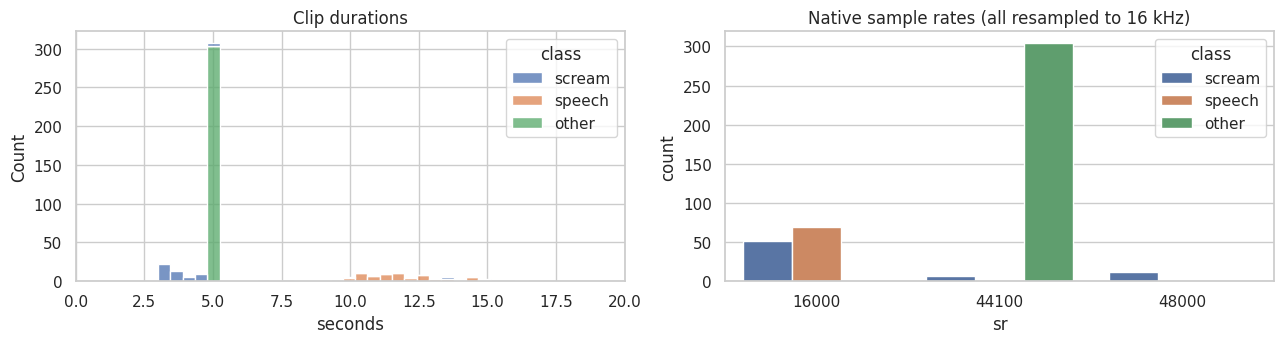

In [3]:
inv = []
for cls in ("scream", "speech", "other"):
    for p in sorted((RAW / cls).glob("*.wav")):
        try:
            info = sf.info(p)
            inv.append({"class": cls, "file": p.name, "sr": info.samplerate, "channels": info.channels, "seconds": info.duration,
                        "category": category_of.get(p.name, cls)})
        except Exception as exc:
            inv.append({"class": cls, "file": p.name, "sr": None, "channels": None, "seconds": None, "category": f"UNREADABLE: {exc}"})
inv = pd.DataFrame(inv)
print(inv.groupby("class").agg(files=("file", "count"), total_min=("seconds", lambda s: s.sum() / 60), mean_s=("seconds", "mean"), median_sr=("sr", "median")).round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
sns.histplot(data=inv, x="seconds", hue="class", bins=30, ax=ax[0], multiple="stack"); ax[0].set_title("Clip durations"); ax[0].set_xlim(0, 20)
sns.countplot(data=inv, x="sr", hue="class", ax=ax[1]); ax[1].set_title("Native sample rates (all resampled to 16 kHz)")
plt.tight_layout(); plt.show()

## 2. Data cleaning
* unreadable / corrupt files → dropped (and listed)
* clips shorter than 0.3 s → dropped
* **exact duplicates** (same decoded samples under two names) → dropped, otherwise the same scream could land in both train and test
* the `negative/` folder contains one laughter clip — moved to the `other` class where it belongs

In [4]:
clips, rejected, seen = [], [], {}
for _, r in inv.iterrows():
    cls = r["class"]; path = RAW / cls / r["file"]
    if r["sr"] is None:
        rejected.append((r["file"], "unreadable")); continue
    if r["seconds"] < 0.3:
        rejected.append((r["file"], "too short")); continue
    y, _ = AF.load_audio(path)
    digest = hashlib.md5(np.round(y[:48000] * 2 ** 15).astype(np.int16).tobytes()).hexdigest()
    if digest in seen:
        rejected.append((r["file"], f"duplicate of {seen[digest]}")); continue
    seen[digest] = r["file"]
    if "laughter" in r["file"]:
        cls = "other"
    clips.append({"clip_id": r["file"], "label": {"scream": "scream", "speech": "normal_speech", "other": "other_sound"}[cls],
                  "category": category_of.get(r["file"], "speech" if cls == "speech" else cls), "y": y, "seconds": len(y) / AF.SR})
print(f"kept {len(clips)} clips; rejected {len(rejected)}:", rejected[:8])
print(pd.Series([c["label"] for c in clips]).value_counts())

kept 442 clips; rejected 2: [('abuse_female_screaming-and-why.wav', 'duplicate of 343916__reitanna__screaming-and-why.wav'), ('clnsp1011.wav', 'duplicate of clnsp1006.wav')]
other_sound      304
scream            70
normal_speech     68
Name: count, dtype: int64


## 3. Windowing + feature extraction
Each clip is cut into 1.5 s windows (0.75 s hop). Window-level cleaning:
* windows quieter than −50 dBFS are silence → dropped
* **windows containing digital silence** (>5 % exact zeros) are dropped. ESC-50 pads short events with zeros, and
  scream/speech clips don't — keeping those windows would let a model learn "abrupt zero padding = other sound", which
  is a dataset artefact, not acoustics.
* at most 10 windows per clip, so one long recording can't dominate its class.

Features are loudness-invariant (each window is peak-normalised): the three sources were recorded and mastered at
different gains, and absolute loudness would otherwise leak the *source* instead of the *sound*.

In [5]:
rows, t0 = [], time.time()
for c in clips:
    wins = []
    for w in AF.split_windows(c["y"]):
        if np.mean(np.abs(w) < 1e-4) > 0.05:
            continue
        wins.append(w)
    if len(wins) > 10:
        wins = [wins[i] for i in sorted(rng.choice(len(wins), 10, replace=False))]
    for k, w in enumerate(wins):
        rows.append({"clip_id": c["clip_id"], "label": c["label"], "category": c["category"], "win": k, **dict(zip(AF.FEATURE_NAMES, AF.window_features(w)))})
feat = pd.DataFrame(rows)
print(f"{len(feat):,} windows from {feat.clip_id.nunique()} clips in {time.time()-t0:.0f}s")
feat.groupby("label").agg(windows=("clip_id", "size"), clips=("clip_id", "nunique"))

1,877 windows from 393 clips in 14s


,windows,clips
label,,
normal_speech,454,68
other_sound,1139,259
scream,284,66


In [6]:
# Final data-quality pass on the feature table
before = len(feat)
feat = feat.replace([np.inf, -np.inf], np.nan).dropna(subset=AF.FEATURE_NAMES)
feat = feat.drop_duplicates(subset=AF.FEATURE_NAMES).reset_index(drop=True)
print(f"dropped {before-len(feat)} NaN/duplicate windows -> {len(feat):,}")
print("constant columns:", [c for c in AF.FEATURE_NAMES if feat[c].nunique() <= 1])
feat.to_csv(DATA_DIR / "tone_features_real.csv", index=False)

dropped 0 NaN/duplicate windows -> 1,877
constant columns: []


### 3b. Optional — add a `fear_distress` class from RAVDESS (not executed in this build)
Download *Audio_Speech_Actors_01-24.zip* from Zenodo (record 1188976), unzip into `data/external/emotional_speech/`,
set `ADD_FEAR_CLASS = True`, and re-run from section 3. File names look like `03-01-06-01-02-01-12.wav`
(3rd number = emotion; `06` = fearful, `01`/`02` = neutral/calm).

In [7]:
ADD_FEAR_CLASS = False
EXTERNAL = DATA_DIR / "external" / "emotional_speech"
if ADD_FEAR_CLASS and EXTERNAL.exists():
    extra = []
    for p in EXTERNAL.rglob("*.wav"):
        emo = p.stem.split("-")[2] if p.stem.count("-") == 6 else None
        if emo in ("06", "01", "02"):
            y, _ = AF.load_audio(p)
            for k, w in enumerate(AF.split_windows(y)[:4]):
                extra.append({"clip_id": p.name, "label": "fear_distress" if emo == "06" else "normal_speech", "category": "ravdess",
                              "win": k, **dict(zip(AF.FEATURE_NAMES, AF.window_features(w)))})
    feat = pd.concat([feat, pd.DataFrame(extra)], ignore_index=True)
    print("RAVDESS windows added:", len(extra))

## 4. Exploratory data analysis

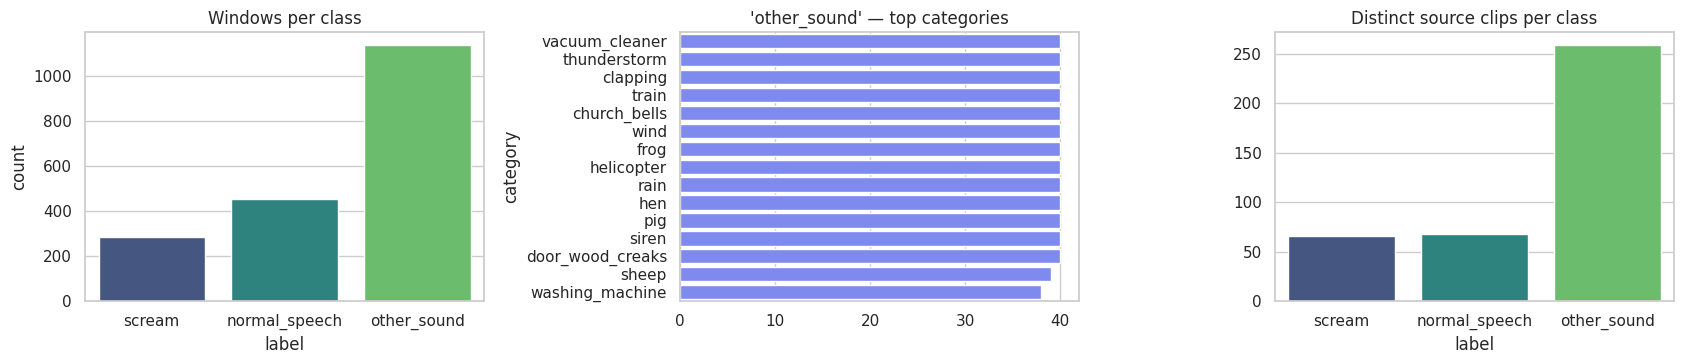

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
order = ["scream", "normal_speech", "other_sound"]
sns.countplot(data=feat, x="label", order=order, ax=axes[0], palette="viridis"); axes[0].set_title("Windows per class")
top = feat[feat.label == "other_sound"].category.value_counts().head(15)
sns.barplot(x=top.values, y=top.index, ax=axes[1], color="#6C7BFF"); axes[1].set_title("'other_sound' — top categories")
pc = feat.groupby("label").clip_id.nunique().reindex(order)
sns.barplot(x=pc.index, y=pc.values, ax=axes[2], palette="viridis"); axes[2].set_title("Distinct source clips per class")
plt.tight_layout(); plt.show()

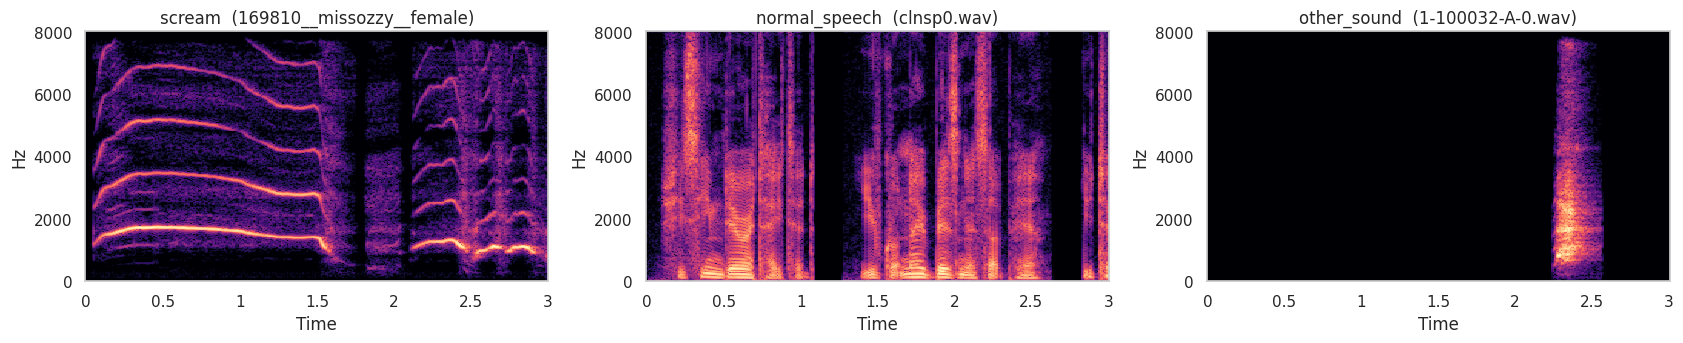

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, label in zip(axes, order):
    c = next(c for c in clips if c["label"] == label and c["seconds"] > 2)
    S = librosa.amplitude_to_db(np.abs(librosa.stft(c["y"][: AF.SR * 3], n_fft=512, hop_length=160)), ref=np.max)
    librosa.display.specshow(S, sr=AF.SR, hop_length=160, x_axis="time", y_axis="hz", ax=ax, cmap="magma"); ax.set_title(f"{label}  ({c['clip_id'][:24]})")
plt.tight_layout(); plt.show()

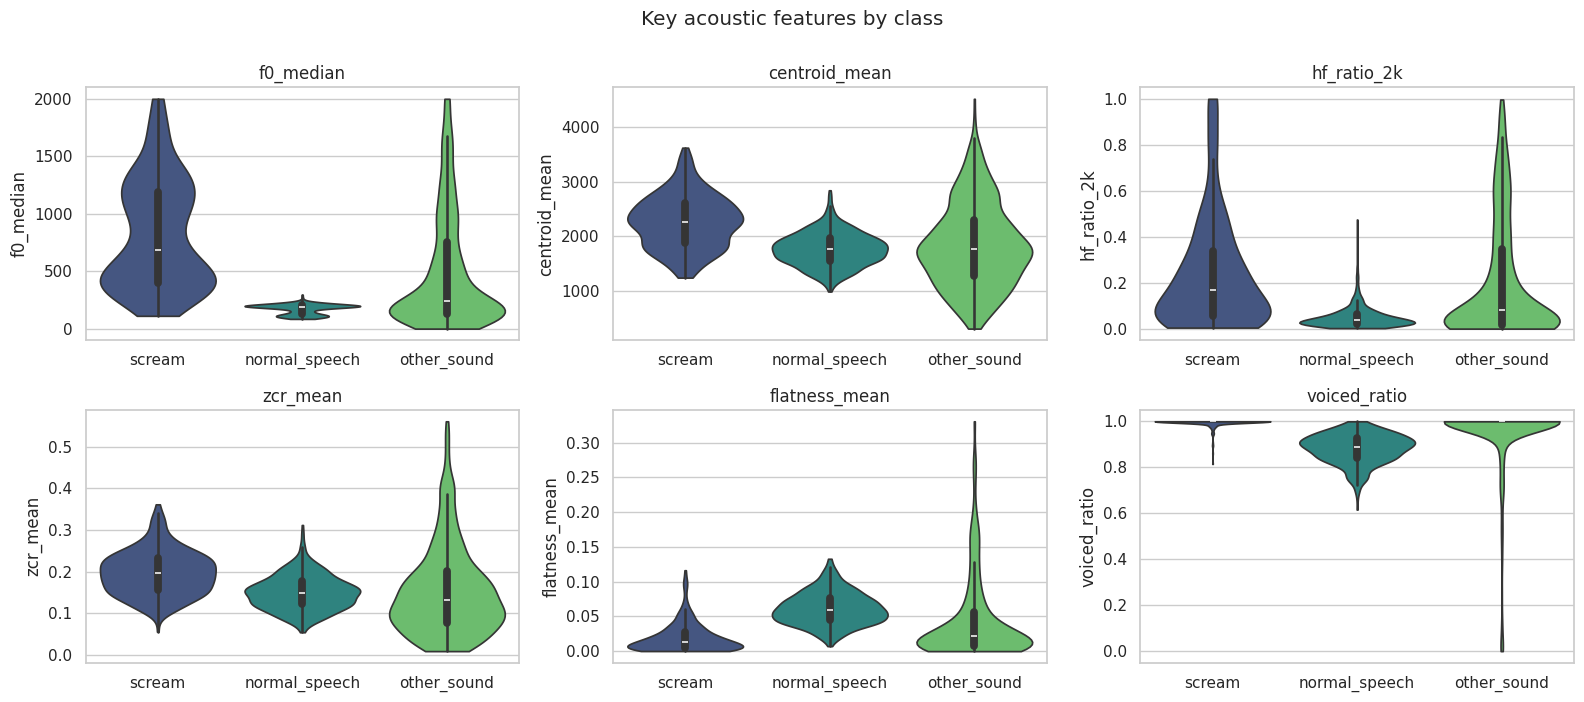

In [10]:
key = ["f0_median", "centroid_mean", "hf_ratio_2k", "zcr_mean", "flatness_mean", "voiced_ratio"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, f in zip(axes.ravel(), key):
    sns.violinplot(data=feat, x="label", y=f, order=order, ax=ax, cut=0, palette="viridis"); ax.set_title(f); ax.set_xlabel("")
plt.suptitle("Key acoustic features by class", y=1.0); plt.tight_layout(); plt.show()

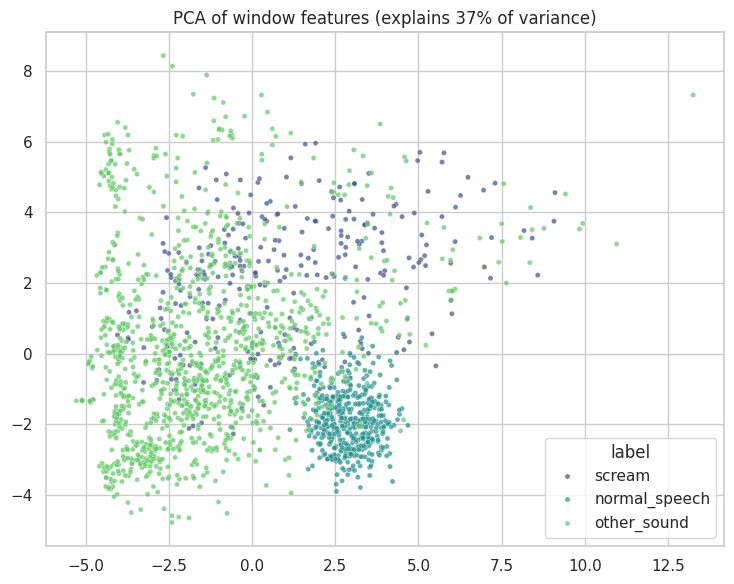

In [11]:
Z = StandardScaler().fit_transform(feat[AF.FEATURE_NAMES]); P = PCA(n_components=2, random_state=RANDOM_SEED).fit(Z)
emb = P.transform(Z)
plt.figure(figsize=(7.5, 6)); sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=feat.label, hue_order=order, s=14, alpha=0.7, palette="viridis")
plt.title(f"PCA of window features (explains {P.explained_variance_ratio_.sum():.0%} of variance)"); plt.tight_layout(); plt.show()

**EDA takeaways** — screams sit at a much higher fundamental frequency with strong high-frequency energy; speech is
low-pitched and voiced; `other_sound` is the broad, noisy class that includes the confusers (laughing, crying baby).
The PCA view shows real overlap between screams and some `other_sound` windows, so we should expect *some* confusion —
and we'll look at exactly which ESC-50 categories cause it.

## 5. Feature engineering & selection
Beyond the 40 raw descriptors we add three ratios that capture the *shape* of a scream, then prune
near-constant and highly-redundant columns (|r| > 0.97) so the models aren't fed 40 near-copies of the same thing.

In [12]:
add_ratios = AF.add_ratio_features      # shared with the serving code
RATIO_FEATURES = AF.RATIO_FEATURES
feat = add_ratios(feat)
candidates_cols = AF.FEATURE_NAMES + RATIO_FEATURES
var_ok = [c for c in candidates_cols if feat[c].std() > 1e-8]
corr = feat[var_ok].corr().abs(); upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
drop = [c for c in upper.columns if (upper[c] > 0.97).any()]
SELECTED = [c for c in var_ok if c not in drop]
print(f"{len(candidates_cols)} candidate features -> {len(SELECTED)} after pruning (dropped {len(drop)}: {drop})")

43 candidate features -> 43 after pruning (dropped 0: [])


## 6. Split — by **recording**, never by window
Neighbouring windows of one recording are near-identical. A random window split would put siblings on both sides and
report fantasy accuracy. We hold out whole clips (`GroupShuffleSplit`) and use `GroupKFold` for model comparison.

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_SEED)
tr_i, te_i = next(gss.split(feat, feat.label, groups=feat.clip_id))
train, test = feat.iloc[tr_i].reset_index(drop=True), feat.iloc[te_i].reset_index(drop=True)
X_train, y_train, g_train = train[SELECTED].to_numpy(), train.label.to_numpy(), train.clip_id.to_numpy()
X_test, y_test = test[SELECTED].to_numpy(), test.label.to_numpy()
assert not set(train.clip_id) & set(test.clip_id)
print(pd.DataFrame({"train windows": train.label.value_counts(), "test windows": test.label.value_counts(),
                    "train clips": train.groupby("label").clip_id.nunique(), "test clips": test.groupby("label").clip_id.nunique()}))

               train windows  test windows  train clips  test clips
label                                                              
normal_speech            379            75           56          12
other_sound              834           305          191          68
scream                   199            85           47          19


## 7. Model selection
Five candidates (class-balanced): Dummy floor, Logistic Regression, RBF-SVM, Random Forest, Hist Gradient Boosting.
The headline metric is **macro-F1**; we also track **scream recall** (a missed scream is the costly error) and
**scream precision** (false alarms erode trust).

In [14]:
candidates = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5))]),
    "RBF SVM": Pipeline([("sc", StandardScaler()), ("m", SVC(C=3, gamma="scale", class_weight="balanced", probability=True, random_state=RANDOM_SEED))]),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=250, learning_rate=0.06, class_weight="balanced", random_state=RANDOM_SEED),
}
from sklearn.metrics import make_scorer, recall_score, precision_score
sc_rec = make_scorer(lambda y, p: recall_score(y, p, labels=["scream"], average="macro", zero_division=0))
sc_prec = make_scorer(lambda y, p: precision_score(y, p, labels=["scream"], average="macro", zero_division=0))
scoring = {"macro_f1": "f1_macro", "balanced_acc": "balanced_accuracy", "scream_recall": sc_rec, "scream_precision": sc_prec}
res, folds = [], {}
for name, model in candidates.items():
    t0 = time.time(); r = cross_validate(model, X_train, y_train, groups=g_train, cv=GroupKFold(n_splits=5), scoring=scoring)
    folds[name] = r["test_macro_f1"]
    res.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring}, "macro_f1_std": r["test_macro_f1"].std(), "fit_s": (time.time() - t0) / 5})
cv_table = pd.DataFrame(res).sort_values("macro_f1", ascending=False).reset_index(drop=True)
cv_table.round(4)

,model,macro_f1,balanced_acc,scream_recall,scream_precision,macro_f1_std,fit_s
0,Hist Gradient Boosting,0.9389,0.9422,0.8626,0.8617,0.0173,1.0822
1,Random Forest,0.9373,0.9258,0.7927,0.9322,0.0286,1.3524
2,Logistic Regression,0.9371,0.9470,0.8890,0.8396,0.0074,0.0165
3,RBF SVM,0.9236,0.9172,0.7792,0.8686,0.0406,0.0774
4,Dummy (majority),0.2475,0.3333,0.0000,0.0000,0.0053,0.0063


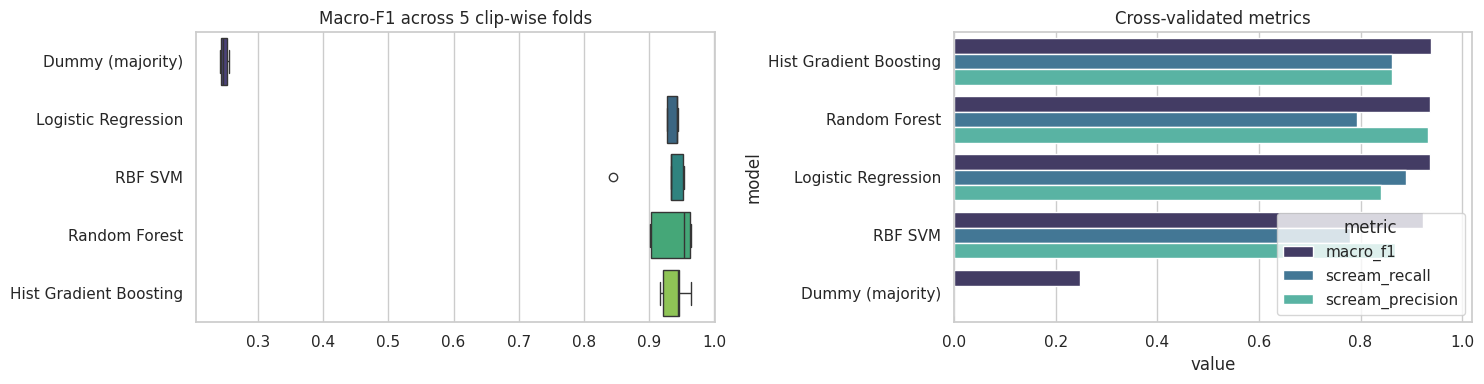

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=pd.DataFrame(folds), orient="h", ax=axes[0], palette="viridis"); axes[0].set_title("Macro-F1 across 5 clip-wise folds")
m = cv_table.melt(id_vars="model", value_vars=["macro_f1", "scream_recall", "scream_precision"], var_name="metric")
sns.barplot(data=m, y="model", x="value", hue="metric", ax=axes[1], palette="mako"); axes[1].set_xlim(0, 1.02); axes[1].set_title("Cross-validated metrics")
plt.tight_layout(); plt.show()

## 8. Hyper-parameter tuning & best-model selection
The two best non-trivial models are tuned with a randomized search under the same clip-wise folds.

In [16]:
spaces = {
    "Random Forest": (RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED),
                      {"n_estimators": [300, 600], "max_depth": [6, 10, 16, None], "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", 0.4, 0.7]}),
    "Hist Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_SEED),
                               {"learning_rate": [0.03, 0.06, 0.1], "max_iter": [150, 300], "max_leaf_nodes": [7, 15, 31], "min_samples_leaf": [5, 10, 20], "l2_regularization": [0, 0.5, 2]}),
    "RBF SVM": (Pipeline([("sc", StandardScaler()), ("m", SVC(class_weight="balanced", probability=True, random_state=RANDOM_SEED))]),
                {"m__C": [0.5, 1, 3, 10, 30], "m__gamma": ["scale", 0.01, 0.003]}),
    "Logistic Regression": (Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=3000, class_weight="balanced"))]), {"m__C": [0.05, 0.2, 1, 5]}),
}
top = [n for n in cv_table.model if n in spaces][:2]
tuned = {}
for n in top:
    est, grid = spaces[n]
    s = RandomizedSearchCV(est, grid, n_iter=8, scoring="f1_macro", cv=GroupKFold(n_splits=4), random_state=RANDOM_SEED, n_jobs=1)
    t0 = time.time(); s.fit(X_train, y_train, groups=g_train); tuned[n] = s
    print(f"{n:24s} tuned CV macro-F1 = {s.best_score_:.4f}  ({time.time()-t0:.0f}s)   {s.best_params_}")
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_est = tuned[best_name].best_estimator_
print("\n>>> selected model:", best_name)

Hist Gradient Boosting   tuned CV macro-F1 = 0.9423  (23s)   {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 150, 'learning_rate': 0.06, 'l2_regularization': 2}


Random Forest            tuned CV macro-F1 = 0.9420  (55s)   {'n_estimators': 300, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 6}

>>> selected model: Hist Gradient Boosting


## 9. Probability calibration
The backend triggers on `scream_probability ≥ 0.7`; that number should mean something. We compare the raw model against a
sigmoid-calibrated one (sigmoid, not isotonic — the dataset is small and isotonic overfits small data).

scream Brier   raw=0.0436   calibrated=0.0436
using calibrated model for deployment


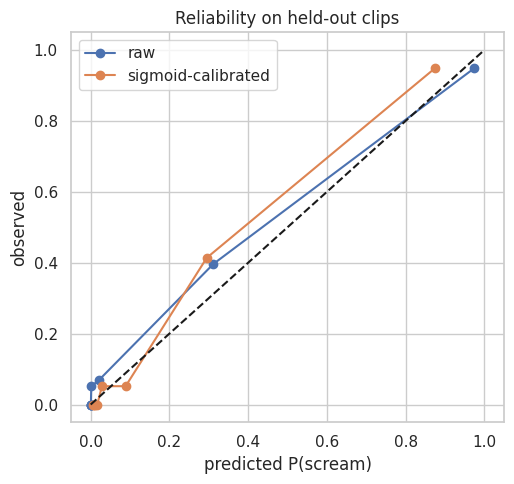

In [17]:
splits = list(GroupKFold(n_splits=4).split(X_train, y_train, g_train))
calibrated = CalibratedClassifierCV(best_est, method="sigmoid", cv=splits).fit(X_train, y_train)
best_est.fit(X_train, y_train)
yb = (y_test == "scream").astype(int)
p_raw = best_est.predict_proba(X_test)[:, list(best_est.classes_).index("scream")]
p_cal = calibrated.predict_proba(X_test)[:, list(calibrated.classes_).index("scream")]
print(f"scream Brier   raw={brier_score_loss(yb, p_raw):.4f}   calibrated={brier_score_loss(yb, p_cal):.4f}")
use_cal = brier_score_loss(yb, p_cal) <= brier_score_loss(yb, p_raw)
final_model = calibrated if use_cal else best_est
print("using", "calibrated" if use_cal else "uncalibrated", "model for deployment")
plt.figure(figsize=(5.3, 5))
for p, lab in ((p_raw, "raw"), (p_cal, "sigmoid-calibrated")):
    fr, mp = calibration_curve(yb, p, n_bins=8, strategy="quantile"); plt.plot(mp, fr, "o-", label=lab)
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("predicted P(scream)"); plt.ylabel("observed"); plt.legend(); plt.title("Reliability on held-out clips"); plt.tight_layout(); plt.show()

## 10. Final evaluation — held-out recordings

               precision    recall  f1-score   support

normal_speech      0.987     0.987     0.987        75
  other_sound      0.915     0.984     0.948       305
       scream      0.935     0.682     0.789        85

     accuracy                          0.929       465
    macro avg      0.946     0.884     0.908       465
 weighted avg      0.930     0.929     0.925       465



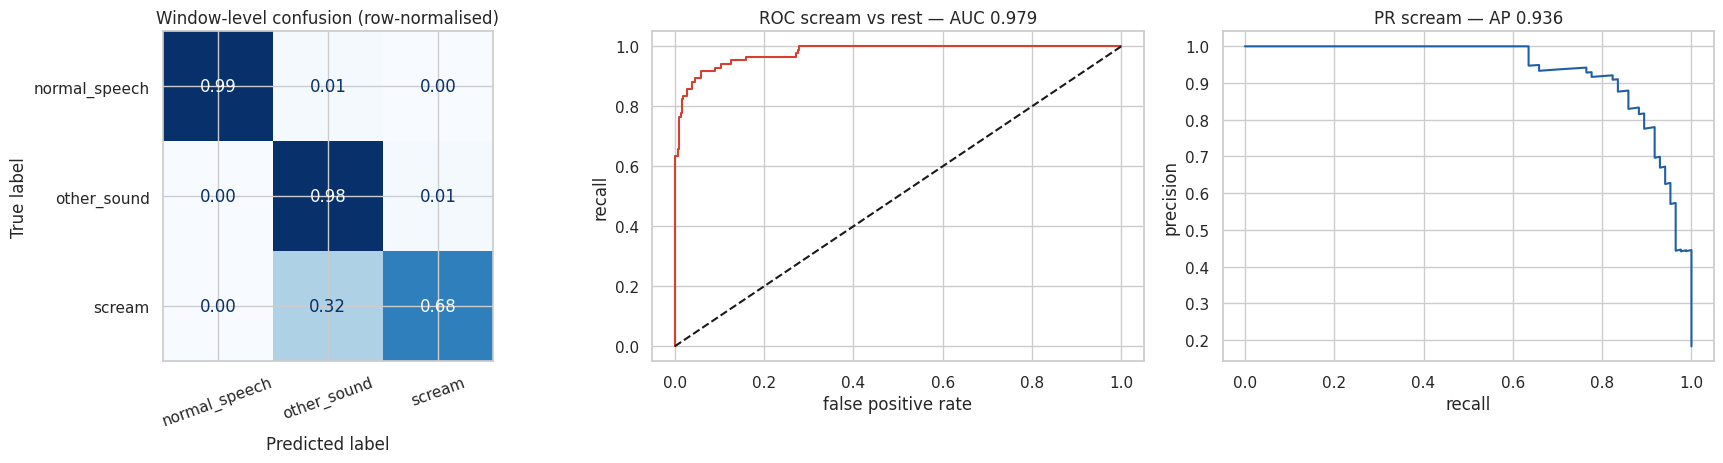

In [18]:
classes = list(final_model.classes_)
proba = final_model.predict_proba(X_test); y_pred = np.array(classes)[proba.argmax(1)]
print(classification_report(y_test, y_pred, digits=3))
report = classification_report(y_test, y_pred, output_dict=True)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=classes, normalize="true"), display_labels=classes).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format=".2f")
axes[0].set_title("Window-level confusion (row-normalised)"); axes[0].tick_params(axis="x", rotation=20)
fpr, tpr, _ = roc_curve(yb, p_cal if use_cal else p_raw); axes[1].plot(fpr, tpr, color="#D6402F"); axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title(f"ROC scream vs rest — AUC {auc(fpr, tpr):.3f}"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("recall")
pr, rc, _ = precision_recall_curve(yb, p_cal if use_cal else p_raw); axes[2].plot(rc, pr, color="#1E5FA8")
axes[2].set_title(f"PR scream — AP {average_precision_score(yb, p_cal if use_cal else p_raw):.3f}"); axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision")
plt.tight_layout(); plt.show()

threshold 0.7:  scream clips caught 68.4% (13/19) | false alarms on non-scream clips 0.0% (0/80)

non-scream categories that triggered a false alarm:
Series([], )


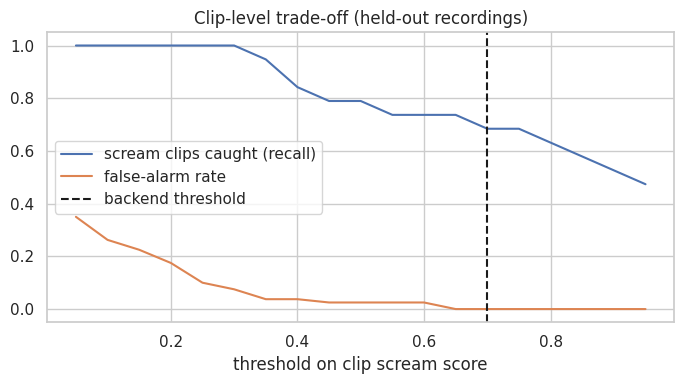

In [19]:
# CLIP level — this mirrors the service exactly: one probability per window, the clip's scream score is the MAX.
test_clips = test.clip_id.unique()
clip_rows = []
for c in test_clips:
    m = test.clip_id == c
    pc = final_model.predict_proba(test.loc[m, SELECTED].to_numpy())[:, classes.index("scream")]
    clip_rows.append({"clip_id": c, "label": test.loc[m, "label"].iloc[0], "category": test.loc[m, "category"].iloc[0], "scream_score": pc.max()})
clip_df = pd.DataFrame(clip_rows)
THRESH = 0.7
clip_df["alarm"] = clip_df.scream_score >= THRESH
sc = clip_df[clip_df.label == "scream"]; non = clip_df[clip_df.label != "scream"]
print(f"threshold {THRESH}:  scream clips caught {sc.alarm.mean():.1%} ({int(sc.alarm.sum())}/{len(sc)}) | false alarms on non-scream clips {non.alarm.mean():.1%} ({int(non.alarm.sum())}/{len(non)})")
print("\nnon-scream categories that triggered a false alarm:")
print(non[non.alarm].groupby("category").size().sort_values(ascending=False).to_string() or "none")
ths = np.linspace(0.05, 0.95, 19)
plt.figure(figsize=(7, 4)); plt.plot(ths, [(sc.scream_score >= t).mean() for t in ths], label="scream clips caught (recall)")
plt.plot(ths, [(non.scream_score >= t).mean() for t in ths], label="false-alarm rate"); plt.axvline(THRESH, color="k", ls="--", label="backend threshold")
plt.xlabel("threshold on clip scream score"); plt.legend(); plt.title("Clip-level trade-off (held-out recordings)"); plt.tight_layout(); plt.show()

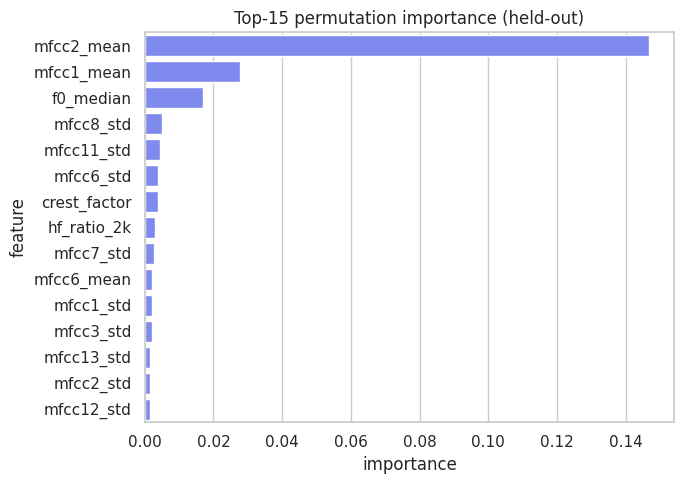

In [20]:
pi = permutation_importance(final_model, X_test, y_test, scoring="f1_macro", n_repeats=6, random_state=RANDOM_SEED)
imp = pd.DataFrame({"feature": SELECTED, "importance": pi.importances_mean}).sort_values("importance", ascending=False).head(15)
plt.figure(figsize=(7, 5)); sns.barplot(data=imp, y="feature", x="importance", color="#6C7BFF"); plt.title("Top-15 permutation importance (held-out)"); plt.tight_layout(); plt.show()

## 11. Robustness — the phone is not a studio
1. **Background noise** at 20/10/5 dB SNR added to held-out recordings.
2. **The real transport path:** phones send AAC/m4a at 64 kbps. We re-encode held-out clips through ffmpeg exactly like that and re-score.

In [21]:
def clip_scores(y_by_clip):
    out = {}
    for c, y in y_by_clip.items():
        X = AF.extract_clip_features(y)
        if len(X) == 0: out[c] = 0.0; continue
        d = add_ratios(pd.DataFrame(X, columns=AF.FEATURE_NAMES))[SELECTED].to_numpy()
        out[c] = float(final_model.predict_proba(d)[:, classes.index("scream")].max())
    return out
held = {c["clip_id"]: c["y"] for c in clips if c["clip_id"] in set(test_clips)}
labels = dict(zip(clip_df.clip_id, clip_df.label))
def summarise(scores):
    s = pd.DataFrame({"score": pd.Series(scores), "label": pd.Series(labels)}); a = s.score >= THRESH
    return (a[s.label == "scream"].mean(), a[s.label != "scream"].mean())
rob = [{"condition": "clean", "scream recall": summarise(clip_scores(held))[0], "false-alarm rate": summarise(clip_scores(held))[1]}]
for snr in (20, 10, 5):
    noisy = {}
    for c, y in held.items():
        p_sig = np.mean(y ** 2) + 1e-12; noisy[c] = (y + rng.normal(0, np.sqrt(p_sig / 10 ** (snr / 10)), len(y))).astype(np.float32)
    a, b = summarise(clip_scores(noisy)); rob.append({"condition": f"+white noise {snr} dB SNR", "scream recall": a, "false-alarm rate": b})
if shutil.which("ffmpeg"):
    aac = {}
    with tempfile.TemporaryDirectory() as td:
        for c, y in held.items():
            src, dst, back = Path(td) / "a.wav", Path(td) / "a.m4a", Path(td) / "b.wav"; sf.write(src, y, AF.SR)
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(src), "-ac", "1", "-ar", "16000", "-b:a", "64k", str(dst)], check=True)
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(dst), "-f", "wav", str(back)], check=True)
            aac[c] = AF.load_audio(back)[0]
    a, b = summarise(clip_scores(aac)); rob.append({"condition": "phone AAC/m4a 64 kbps round-trip", "scream recall": a, "false-alarm rate": b})
else:
    print("ffmpeg not found — skipping codec test (install ffmpeg; the AI service needs it anyway)")
pd.DataFrame(rob).round(3)

,condition,scream recall,false-alarm rate
0,clean,0.684,0.0
1,+white noise 20 dB SNR,0.368,0.0
2,+white noise 10 dB SNR,0.000,0.0
3,+white noise 5 dB SNR,0.000,0.0
4,phone AAC/m4a 64 kbps round-trip,0.737,0.0


## 12. Refit on all recordings and export
The selected, tuned configuration is refit on **all** clips; the metadata records the honest held-out numbers from step 10.

In [22]:
X_all, y_all, g_all = feat[SELECTED].to_numpy(), feat.label.to_numpy(), feat.clip_id.to_numpy()
base = type(best_est)(**best_est.get_params())
deploy = CalibratedClassifierCV(base, method="sigmoid", cv=list(GroupKFold(n_splits=4).split(X_all, y_all, g_all))).fit(X_all, y_all) if use_cal else base.fit(X_all, y_all)
joblib.dump(deploy, ARTIFACTS_DIR / "tone_classifier.pkl")
meta = {
    "model_name": f"{best_name}" + (" + sigmoid calibration" if use_cal else ""),
    "feature_names": SELECTED, "all_extracted_features": AF.FEATURE_NAMES, "ratio_features": RATIO_FEATURES,
    "class_labels": list(deploy.classes_),
    "audio": {"sample_rate": AF.SR, "window_s": AF.WIN_S, "hop_s": AF.HOP_S, "min_window_rms_db": AF.MIN_WINDOW_RMS_DB, "aggregation": "max over windows"},
    "trained_on": "71 real scream clips + 69 real clean-speech clips (Varun-310/SCREAM) + 304 ESC-50 environmental clips (38 categories)",
    "evaluation": {"protocol": "25% of recordings held out (GroupShuffleSplit by clip); CV is GroupKFold by clip",
                   "window_macro_f1": float(f1_score(y_test, y_pred, average="macro")), "window_accuracy": float(report["accuracy"]),
                   "scream_window_f1": float(report["scream"]["f1-score"]), "scream_auc": float(auc(fpr, tpr)),
                   f"clip_scream_recall_at_{THRESH}": float(sc.alarm.mean()), f"clip_false_alarm_rate_at_{THRESH}": float(non.alarm.mean()),
                   "cv_macro_f1_by_model": {r["model"]: float(r["macro_f1"]) for r in res}},
    "sklearn_version": sklearn.__version__, "librosa_version": librosa.__version__,
    "limitations": ["Only 71 scream recordings (many from the same sound libraries) — treat reported accuracy as optimistic.",
                    "No fearful-speech class; fear_probability is reported as 0 unless you add one (section 3b).",
                    "Re-validate on audio recorded by your own users' phones before relying on it alone."],
}
(ARTIFACTS_DIR / "tone_classifier_metadata.json").write_text(json.dumps(meta, indent=2))
print("saved tone_classifier.pkl + metadata; classes:", meta["class_labels"])

saved tone_classifier.pkl + metadata; classes: ['normal_speech', 'other_sound', 'scream']


## 13. Serving-contract test
Run the saved artefact through the same steps `tone_analysis_service.py` performs on an uploaded clip.

In [23]:
loaded = joblib.load(ARTIFACTS_DIR / "tone_classifier.pkl"); m = json.loads((ARTIFACTS_DIR / "tone_classifier_metadata.json").read_text())
def analyse(path):
    y, _ = AF.load_audio(path); X = AF.extract_clip_features(y)
    if not len(X): return {"scream_probability": 0.0}
    d = add_ratios(pd.DataFrame(X, columns=AF.FEATURE_NAMES))[m["feature_names"]].to_numpy()
    p = loaded.predict_proba(d); i = list(loaded.classes_).index("scream")
    return {"scream_probability": round(float(p[:, i].max()), 3), "windows": len(d)}
demo_s = next(RAW.glob("scream/femaleScream-0*.wav")); demo_n = next(RAW.glob("speech/*.wav"))
print("scream clip:", demo_s.name, analyse(demo_s)); print("speech clip:", demo_n.name, analyse(demo_n))

scream clip: femaleScream-004.wav {'scream_probability': 0.734, 'windows': 6}


speech clip: clnsp1010.wav {'scream_probability': 0.016, 'windows': 12}


## 14. Conclusions & next steps
* Trained and evaluated on **real recordings**; evaluation is by held-out *recording*, plus a clip-level view that mirrors the service.
* The notebook names the confusers (ESC-50 categories that still trigger false alarms) instead of hiding them.
* **Limits to state in your project report:** small scream corpus; no fearful speech; lab recordings.
* **Highest-value next step:** with consent, store a few seconds of audio around every *confirmed-real* SOS and every *false alarm*
  (the new Evidence Vault already stores chunks + the user's "false alarm" verdict) — that becomes your own labelled,
  phone-recorded, India-specific training set.